# Classification d’intentions pour un chatbot bancaire

**Module : NLP — Projet 6**  
**Dataset : Banking77 — 77 intentions**

## Objectif et livrables

Le projet associe une question bancaire en anglais à une intention, puis à une réponse préenregistrée. Le pipeline couvre l’exploration, un dictionnaire de variantes, le prétraitement, les embeddings de phrases, la classification SVM, l’évaluation et une application Streamlit.

La version locale génère des embeddings **LSA** denses, non contextuels, sans téléchargement. Une option **Sentence-BERT** est disponible dans le même pipeline pour un environnement disposant des dépendances et du modèle préentraîné. Les résultats de ces méthodes sont distingués explicitement.

Le test fourni est réservé à l’évaluation finale. La validation et le choix de C reposent uniquement sur une séparation de l’entraînement. Les doublons entre entraînement et test sont exclus de l’entraînement avant cette séparation.


## 1. Environnement et modules partagés

Les dépendances locales sont décrites dans `requirements.txt`. Les fonctions de `banking77.py` sont communes à l’entraînement et à l’application. L’exécution ne dépend d’aucune cellule cachée et ne contient aucune saisie bloquante.


In [1]:
import os
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', str(Path.cwd() / '.cache' / 'matplotlib'))

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from threadpoolctl import threadpool_limits

from banking77 import (
    BASE_DIR, RANDOM_STATE, charger_variantes, nettoyer_texte,
    preparer_donnees, comparer_modeles, construire_modele, predire_intention,
)
from rapport import exporter_resultats

CONTROLE_THREADS = threadpool_limits(limits=2)
MOTEUR_EMBEDDINGS = os.environ.get('BANKING77_EMBEDDINGS', 'lsa')
ARTIFACTS = BASE_DIR / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
print('Moteur des embeddings :', MOTEUR_EMBEDDINGS)
print('Graine aléatoire :', RANDOM_STATE)


Moteur des embeddings : lsa
Graine aléatoire : 42


## 2. Acquisition, exploration et qualité des données

Les deux fichiers CSV fournis portent les colonnes `text` et `intention`. Le contrôle porte sur les valeurs manquantes, les textes vides, les effectifs, les classes et les doublons après normalisation.


In [2]:
train_brut = pd.read_csv(BASE_DIR / 'banking77_train.csv')
test_brut = pd.read_csv(BASE_DIR / 'banking77_test.csv')
for nom, df in [('Entraînement brut', train_brut), ('Test fourni', test_brut)]:
    print(f'{nom} : {len(df):,} lignes, {df.intention.nunique()} intentions')
    print('Valeurs manquantes :', df.isna().sum().to_dict())
    print('Textes vides :', int(df.text.fillna('').str.strip().eq('').sum()))
display(train_brut.head())


Entraînement brut : 10,003 lignes, 77 intentions
Valeurs manquantes : {'text': 0, 'intention': 0}
Textes vides : 0
Test fourni : 3,080 lignes, 77 intentions
Valeurs manquantes : {'text': 0, 'intention': 0}
Textes vides : 0


,text,intention
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival
3,Can I track my card while it is in the process...,card_arrival
4,"How do I know if I will get my card, or if it ...",card_arrival


In [3]:
train, test, bilan = preparer_donnees()
display(pd.DataFrame([bilan]).T.rename(columns={0: 'nombre'}))
assert len(test) == len(test_brut), 'Le test fourni doit être conservé.'
assert set(train.intention) == set(test.intention)
print('Intentions communes :', train.intention.nunique())


Intentions communes : 77


,nombre
train_initial,10003
test_initial,3080
lignes_invalides_train,0
lignes_invalides_test,0
recouvrements_train_test,24
conflits_etiquettes_train,2
doublons_internes_train,27
train_final,9950
test_final,3080
classes,77


Les textes communs au test sont retirés de l’entraînement ; les doublons internes de l’entraînement sont ensuite réduits à un exemple. Les fichiers CSV d’origine ne sont pas modifiés. Les textes d’entraînement associés à plusieurs intentions après normalisation sont tous exclus, sans arbitrage d’étiquette. Ce contrôle évite la mémorisation de questions identiques pendant l’évaluation.


,train,test
count,77.00,77.0
mean,129.22,40.0
std,33.16,0.0
min,35.00,40.0
25%,111.00,40.0
50%,126.00,40.0
75%,159.00,40.0
max,187.00,40.0


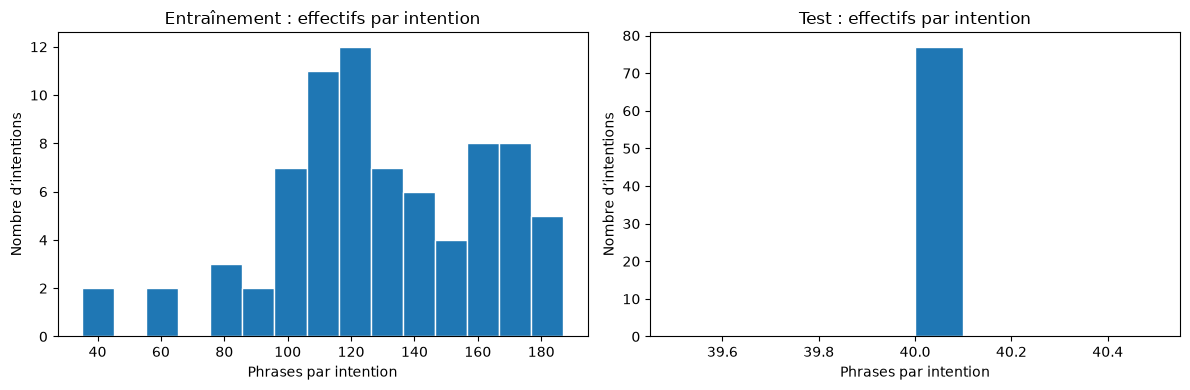

In [4]:
repartition_train = train.intention.value_counts()
repartition_test = test.intention.value_counts()
display(pd.DataFrame({'train': repartition_train, 'test': repartition_test}).describe().round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(repartition_train, bins=15, edgecolor='white')
axes[0].set_title('Entraînement : effectifs par intention')
axes[1].hist(repartition_test, bins=10, edgecolor='white')
axes[1].set_title('Test : effectifs par intention')
for ax in axes:
    ax.set_xlabel('Phrases par intention')
    ax.set_ylabel('Nombre d’intentions')
fig.tight_layout()
fig.savefig(ARTIFACTS / 'distribution_classes.png', dpi=150, bbox_inches='tight')
plt.show()


## 3. Prétraitement et dictionnaire de variantes

La normalisation conserve les négations et la ponctuation. Le dictionnaire `variantes.json` regroupe des contractions, des abréviations et quelques variantes bancaires contrôlées. Les remplacements respectent les limites des mots ; aucune suppression globale de mots vides n’est appliquée. Le dictionnaire est embarqué dans le pipeline sauvegardé.


In [5]:
variantes = charger_variantes()
display(pd.DataFrame(variantes.items(), columns=['variante', 'forme normalisée']))
exemples_nettoyage = [
    "  I CAN’T find my creditcard.  ",
    "The cash machine did not return my card.",
    "My top-up hasn't arrived yet!",
]
display(pd.DataFrame({
    'texte original': exemples_nettoyage,
    'texte normalisé': [nettoyer_texte(t, variantes) for t in exemples_nettoyage],
}))


,variante,forme normalisée
0,can't,can not
1,cannot,can not
2,won't,will not
3,don't,do not
4,doesn't,does not
5,didn't,did not
6,isn't,is not
7,aren't,are not
8,wasn't,was not
9,weren't,were not


,texte original,texte normalisé
0,I CAN’T find my creditcard.,i can not find my credit card.
1,The cash machine did not return my card.,the atm did not return my card.
2,My top-up hasn't arrived yet!,my top up has not arrived yet!


## 4. Séparation entraînement / validation

Une séparation stratifiée réserve 20 % de l’entraînement nettoyé à la validation. Les indices sont conservés pour rendre le protocole vérifiable. Le test fourni n’intervient pas dans le choix du modèle.


In [6]:
indices_train, indices_val = train_test_split(
    np.arange(len(train)), test_size=0.20,
    random_state=RANDOM_STATE, stratify=train.intention,
)
X_train = train.iloc[indices_train].text
X_val = train.iloc[indices_val].text
y_train = train.iloc[indices_train].intention
y_val = train.iloc[indices_val].intention
print('Entraînement de travail :', len(X_train))
print('Validation :', len(X_val))
print('Test final :', len(test))
print('Classes dans train / validation :', y_train.nunique(), '/', y_val.nunique())
assert set(indices_train).isdisjoint(indices_val)


Entraînement de travail : 7960
Validation : 1990
Test final : 3080
Classes dans train / validation : 77 / 77


## 5. Embeddings de phrases et comparaison des modèles

La référence lexicale utilise des n-grammes de mots et de caractères pondérés par TF-IDF. La **LSA** projette cette matrice dans un espace latent de 256 dimensions par SVD tronquée : pour une matrice de documents $A$ et les composantes $V_k$, l’embedding d’une phrase est obtenu par $A V_k^T$, puis normalisé en norme L2. Le vocabulaire, l’IDF et les composantes sont appris uniquement sur l’entraînement de travail à cette étape.

Trois représentations sont comparées avec un SVM linéaire et C dans {0,5 ; 1 ; 3} : TF-IDF seul, embeddings seuls, et combinaison hybride TF-IDF + embeddings pondérés par 0,5. Le modèle livré inclut des embeddings ; TF-IDF seul fournit une référence. La sélection maximise la F1 macro de validation parmi les deux représentations incluant des embeddings. Les égalités sont départagées par l’accuracy, puis par le plus petit C.

L’option Sentence-BERT remplace la projection LSA par les vecteurs normalisés de `sentence-transformers/all-MiniLM-L6-v2`, sans ajustement de l’encodeur sur Banking77. Aucun résultat Sentence-BERT n’est déclaré pour une exécution LSA.


In [7]:
comparaison, selection = comparer_modeles(X_train, y_train, X_val, y_val, moteur=MOTEUR_EMBEDDINGS)
display(comparaison.round(4))
print('Configuration retenue :', selection)


Validation — tfidf, C=0.5 : F1 macro=0.9057
Validation — tfidf, C=1.0 : F1 macro=0.9049
Validation — tfidf, C=3.0 : F1 macro=0.9004
Validation — embeddings, C=0.5 : F1 macro=0.8822
Validation — embeddings, C=1.0 : F1 macro=0.8872
Validation — embeddings, C=3.0 : F1 macro=0.8808
Validation — hybride, C=0.5 : F1 macro=0.9083
Validation — hybride, C=1.0 : F1 macro=0.9043
Validation — hybride, C=3.0 : F1 macro=0.9017
Configuration retenue : {'mode': 'hybride', 'C': 0.5, 'moteur': 'lsa'}


,mode,C,accuracy,precision_macro,rappel_macro,f1_macro
0,hybride,0.5,0.9106,0.9124,0.9086,0.9083
1,tfidf,0.5,0.9080,0.9098,0.9062,0.9057
2,tfidf,1.0,0.9075,0.9085,0.9053,0.9049
3,hybride,1.0,0.9065,0.9081,0.9047,0.9043
4,hybride,3.0,0.9045,0.9054,0.9024,0.9017
5,tfidf,3.0,0.9035,0.9045,0.9009,0.9004
6,embeddings,1.0,0.8874,0.8926,0.8862,0.8872
7,embeddings,0.5,0.8844,0.8918,0.8802,0.8822
8,embeddings,3.0,0.8819,0.8851,0.8804,0.8808


## 6. Entraînement final et génération des embeddings

Après sélection, le pipeline complet est ajusté sur tout l’entraînement nettoyé. Les données de test sont uniquement transformées. Les vecteurs denses et leurs étiquettes sont exportés dans `artifacts/embeddings_phrases.npz`.


In [8]:
modele = construire_modele(**selection)
modele.fit(train.text, train.intention)
normaliseur = modele.named_steps['normalisation']
representation = modele.named_steps['representation']
embeddings = {
    'train': representation.embeddings_phrases(normaliseur.transform(train.text)),
    'test': representation.embeddings_phrases(normaliseur.transform(test.text)),
}
print('Embeddings entraînement :', embeddings['train'].shape)
print('Embeddings test :', embeddings['test'].shape)
if hasattr(representation, 'svd_'):
    print('Variance expliquée par la LSA :', round(float(representation.svd_.explained_variance_ratio_.sum()), 4))
assert np.isfinite(embeddings['train']).all()
assert embeddings['train'].shape[1] == embeddings['test'].shape[1]


Embeddings entraînement : (9950, 256)
Embeddings test : (3080, 256)
Variance expliquée par la LSA : 0.5239


La similarité cosinus dans l’espace dense permet également d’examiner les phrases d’entraînement les plus proches d’une requête. Cette recherche illustre les embeddings ; la prédiction finale reste celle du SVM.


In [9]:
requete = 'My card has not arrived yet'
vecteur = representation.embeddings_phrases(normaliseur.transform([requete]))[0]
similarites = embeddings['train'] @ vecteur
proches = np.argsort(similarites)[-5:][::-1]
voisins = train.iloc[proches].copy()
voisins['similarite_cosinus'] = similarites[proches]
print('Requête de démonstration :', requete)
display(voisins)


Requête de démonstration : My card has not arrived yet


,text,intention,similarite_cosinus
62,My card hasn't arrived.,card_arrival,0.937259
122,Why hasn't my card arrived yet?,card_arrival,0.925775
148,My card hasn't arrived yet. What do I do?,card_arrival,0.878412
2808,Why has my transfer not arrived yet?,transfer_not_received_by_recipient,0.812762
2798,My transfer hasn't arrived,transfer_not_received_by_recipient,0.788276


## 7. Évaluation finale et export des livrables

L’accuracy, la précision macro, le rappel macro et la F1 macro sont calculés sur le test fourni. Le rapport par classe, les erreurs, les confusions, les indices de validation, les versions des dépendances et les empreintes des fichiers sont exportés avec le modèle.


In [10]:
metadonnees, rapport_test, resultats, paires = exporter_resultats(
    modele, train, test, comparaison, selection, bilan, embeddings, indices_train, indices_val,
)
display(pd.DataFrame([metadonnees['scores_test']]).round(4))
classes = list(modele.classes_)
display(rapport_test.loc[classes].sort_values('f1-score').head(12).round(3))


,accuracy,precision_macro,rappel_macro,f1_macro
0,0.9084,0.9111,0.9084,0.9084


,precision,recall,f1-score,support
top_up_failed,0.769,0.750,0.759,40.0
pending_transfer,0.795,0.775,0.785,40.0
balance_not_updated_after_bank_transfer,0.800,0.800,0.800,40.0
failed_transfer,0.761,0.875,0.814,40.0
card_not_working,0.755,0.925,0.831,40.0
transfer_not_received_by_recipient,0.829,0.850,0.840,40.0
why_verify_identity,0.829,0.850,0.840,40.0
top_up_reverted,0.868,0.825,0.846,40.0
card_payment_not_recognised,0.850,0.850,0.850,40.0
unable_to_verify_identity,0.850,0.850,0.850,40.0


## 8. Analyse des erreurs et matrice de confusion

La matrice est normalisée par classe réelle. Chaque ligne décrit la répartition des prédictions pour une intention donnée. Les paires de confusion et les exemples erronés complètent les métriques globales.


In [11]:
erreurs = resultats.loc[resultats.vrai.ne(resultats.predit)]
print(f'Erreurs : {len(erreurs)} sur {len(resultats)} ({len(erreurs) / len(resultats):.2%})')
display(erreurs.head(15))
display(paires.head(15))


Erreurs : 282 sur 3080 (9.16%)


,text,vrai,predit
0,How do I locate my card?,card_arrival,get_physical_card
5,When will I get my card?,card_arrival,card_delivery_estimate
11,How long does a card delivery take?,card_arrival,card_delivery_estimate
32,How do I know when my card will arrive?,card_arrival,card_delivery_estimate
36,I'm starting to think my card is lost because ...,card_arrival,lost_or_stolen_card
79,Can I link another card to my account?,card_linking,getting_spare_card
93,Is it a good time to exchange?,exchange_rate,exchange_charge
106,The exchange rate would be?,exchange_rate,wrong_exchange_rate_for_cash_withdrawal
138,Why am I being charged more ?,card_payment_wrong_exchange_rate,card_payment_fee_charged
145,The exchange rate seems off on this transaction,card_payment_wrong_exchange_rate,wrong_exchange_rate_for_cash_withdrawal


,vrai,predit,nombre
157,top_up_failed,top_up_reverted,5
196,verify_my_identity,why_verify_identity,4
205,why_verify_identity,unable_to_verify_identity,4
6,balance_not_updated_after_bank_transfer,pending_transfer,3
7,balance_not_updated_after_bank_transfer,transfer_not_received_by_recipient,3
20,card_arrival,card_delivery_estimate,3
74,disposable_card_limits,getting_virtual_card,3
94,fiat_currency_support,exchange_via_app,3
96,fiat_currency_support,supported_cards_and_currencies,3
99,get_disposable_virtual_card,getting_virtual_card,3


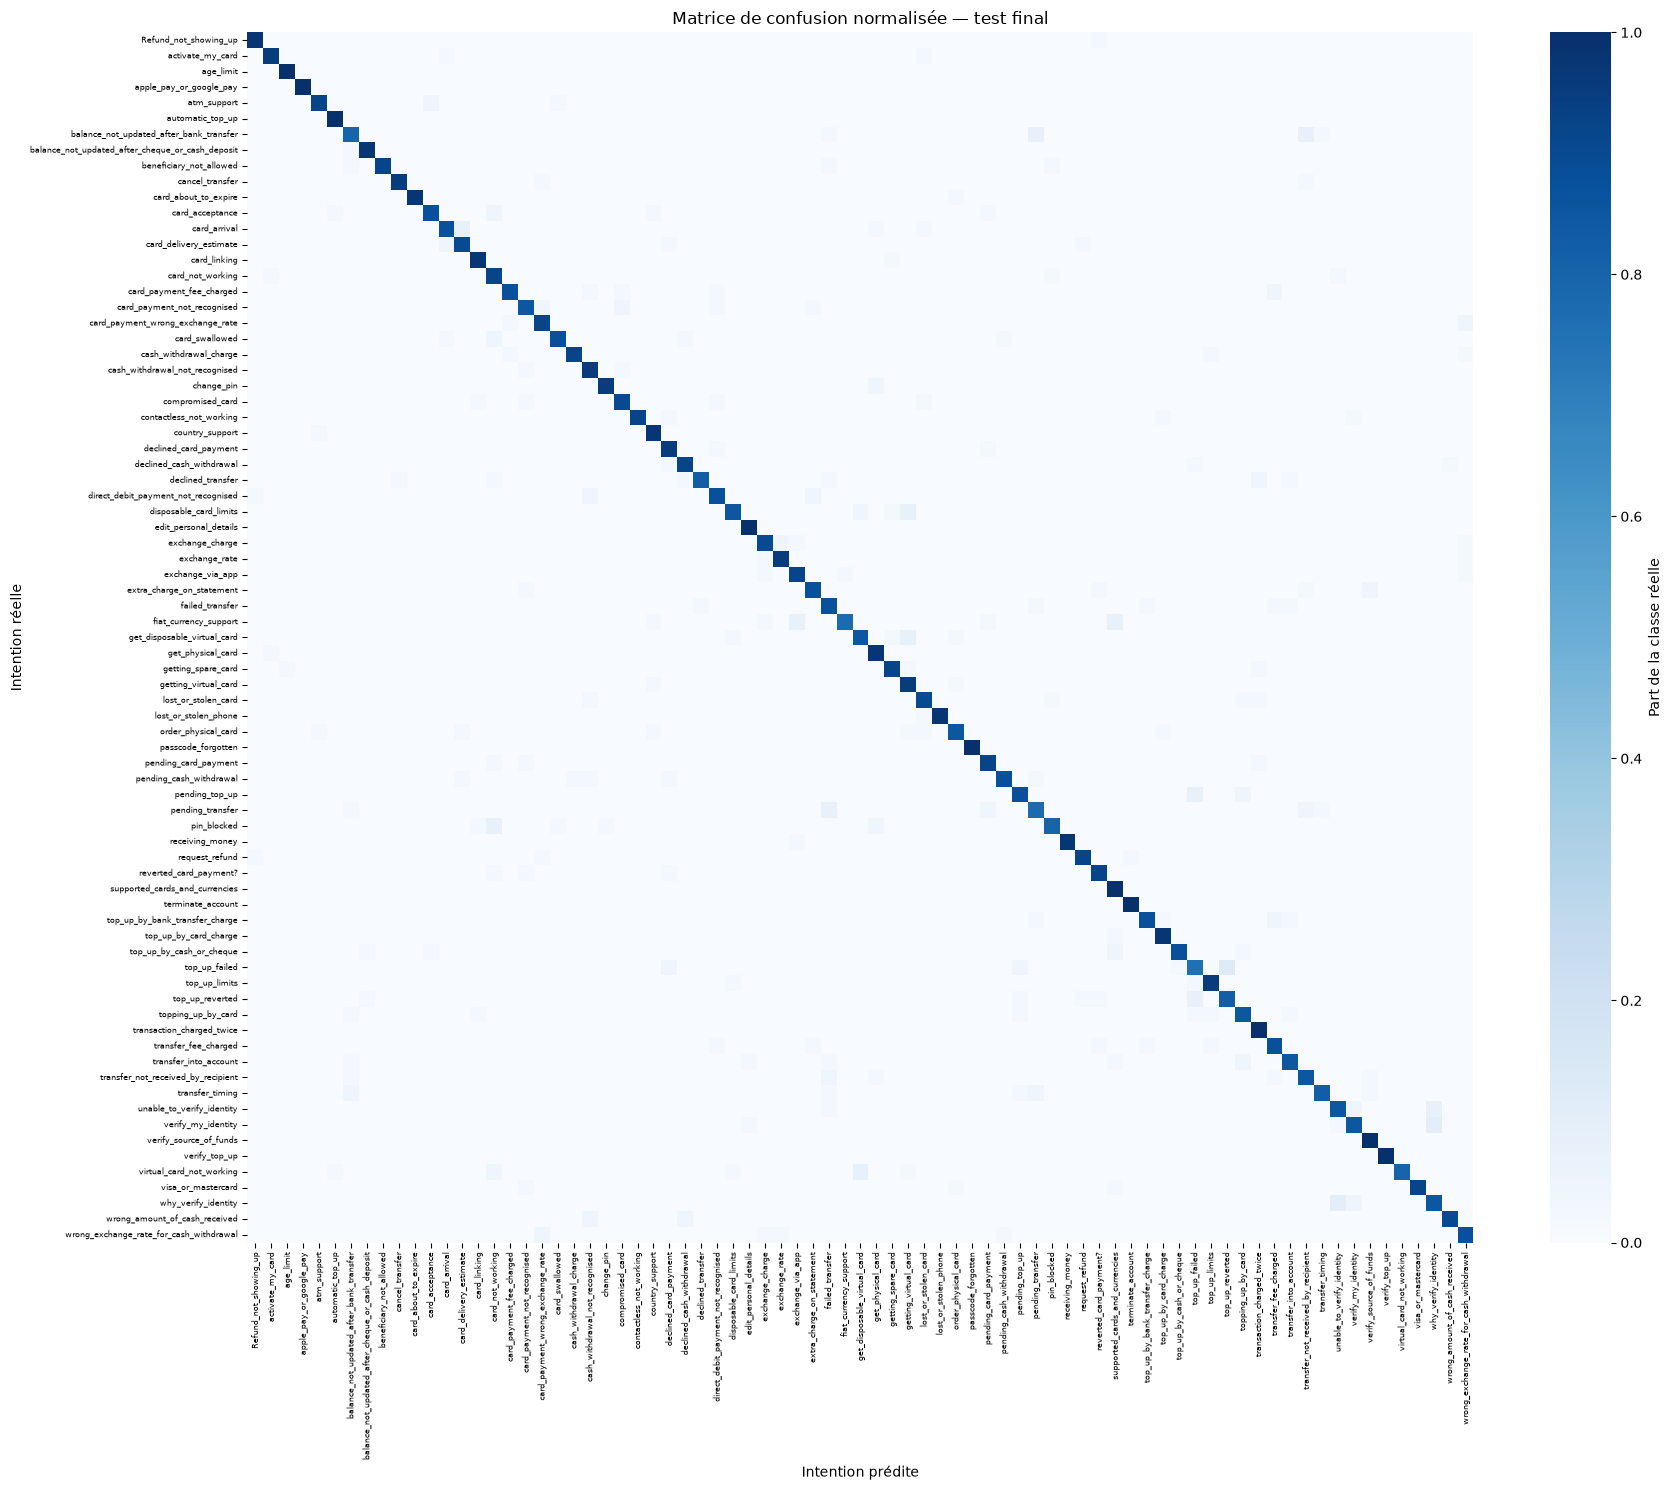

In [12]:
cm = confusion_matrix(resultats.vrai, resultats.predit, labels=classes, normalize='true')
fig, ax = plt.subplots(figsize=(18, 15))
sns.heatmap(cm, cmap='Blues', xticklabels=classes, yticklabels=classes,
            cbar_kws={'label': 'Part de la classe réelle'}, ax=ax)
ax.set_title('Matrice de confusion normalisée — test final')
ax.set_xlabel('Intention prédite')
ax.set_ylabel('Intention réelle')
ax.tick_params(axis='x', labelsize=6, rotation=90)
ax.tick_params(axis='y', labelsize=6, rotation=0)
fig.tight_layout()
fig.savefig(ARTIFACTS / 'matrice_confusion.png', dpi=150, bbox_inches='tight')
plt.show()


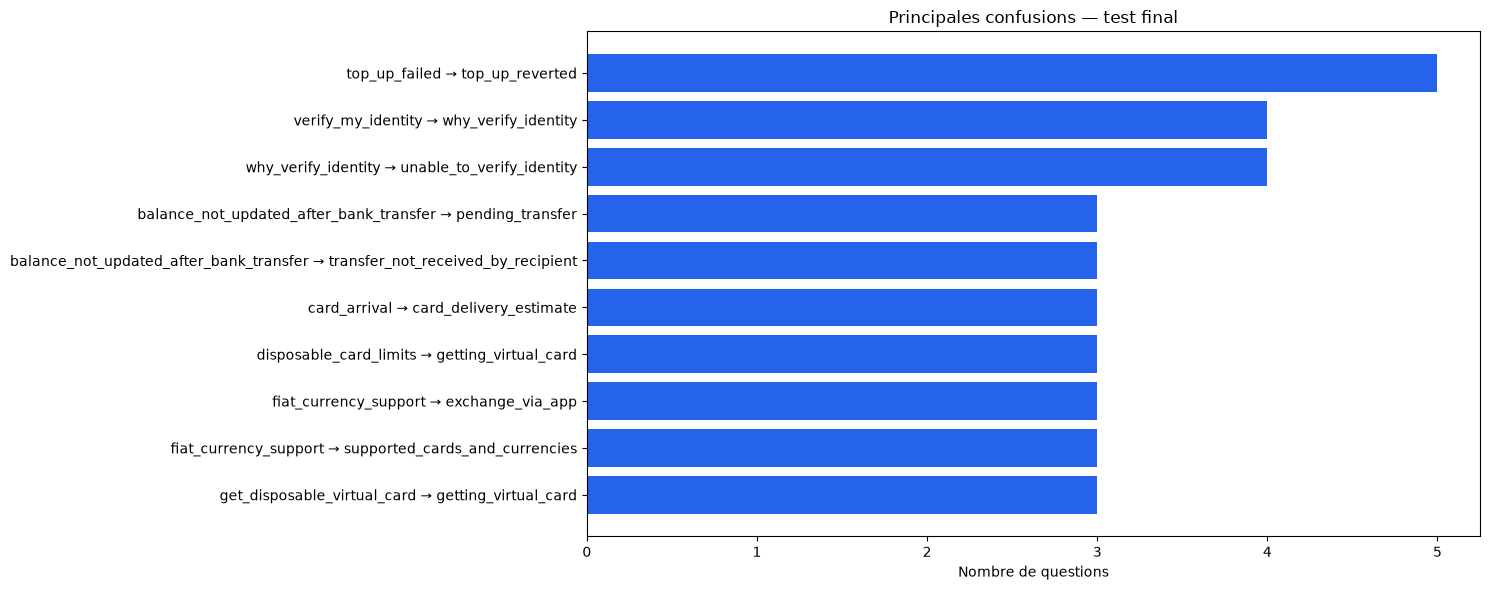

In [13]:
top_confusions = paires.head(10).iloc[::-1]
if not top_confusions.empty:
    etiquettes = [f'{ligne.vrai} → {ligne.predit}' for ligne in top_confusions.itertuples()]
    fig, ax = plt.subplots(figsize=(15, 6))
    ax.barh(etiquettes, top_confusions.nombre, color='#2563eb')
    ax.set_title('Principales confusions — test final')
    ax.set_xlabel('Nombre de questions')
    ax.xaxis.get_major_locator().set_params(integer=True)
    fig.tight_layout()
    fig.savefig(ARTIFACTS / 'confusions_frequentes.png', dpi=150, bbox_inches='tight')
    plt.show()


## 9. Démonstration et réponses préenregistrées

Le dictionnaire de réponses couvre exactement les 77 étiquettes d’origine. Les réponses sont générales, impersonnelles et destinées à une démonstration pédagogique. Aucune procédure propre à une banque n’est présumée.


In [14]:
reponses = json.loads((BASE_DIR / 'reponses.json').read_text(encoding='utf-8'))
questions = [
    'I have not received my new card yet',
    'Why was I charged twice for this payment?',
    'Why have I been charged a fee for cash withdrawal?',
    'How can I create a disposable virtual card?',
]
for question in questions:
    intention = predire_intention(question, modele)
    print('Question :', question)
    print('Intention :', intention)
    print('Réponse :', reponses[intention])
    print()


Question : I have not received my new card yet
Intention : card_arrival
Réponse : This category concerns a card that has not arrived. The delivery status, dispatch date and estimated arrival date are relevant to a delivery review.

Question : Why was I charged twice for this payment?
Intention : transaction_charged_twice
Réponse : This category concerns a possible duplicate charge. Merchant references and the final status of both entries are relevant to confirming a duplicate payment.

Question : Why have I been charged a fee for cash withdrawal?
Intention : cash_withdrawal_charge
Réponse : This category concerns a cash withdrawal fee. Charges may depend on the ATM operator, withdrawal conditions and the bank's applicable tariff.

Question : How can I create a disposable virtual card?
Intention : get_disposable_virtual_card
Réponse : This category concerns obtaining a disposable virtual card. Availability and activation depend on the account type and issuer's supported card services.



In [15]:
# Démonstration libre facultative, sans saisie bloquante pendant une exécution complète.
QUESTION_LIBRE = ''
if QUESTION_LIBRE.strip():
    intention = predire_intention(QUESTION_LIBRE, modele)
    print('Intention prédite :', intention)
    print('Réponse :', reponses[intention])
else:
    print('Aucune question libre configurée.')


Aucune question libre configurée.


## 10. Vérification du modèle sauvegardé et application Streamlit

L’application `app.py` charge `artifacts/modele_intention_banking77.joblib` et `reponses.json`. Le modèle sauvegardé contient la normalisation, la représentation et le SVM. Le lancement est décrit dans `README_APPLICATION.md`.


In [16]:
modele_recharge = joblib.load(ARTIFACTS / 'modele_intention_banking77.joblib')
assert np.array_equal(modele.predict(questions), modele_recharge.predict(questions))
assert set(modele_recharge.classes_) == set(reponses)
print('Prédictions identiques après rechargement.')
print('Réponses disponibles :', len(reponses))
print('Livrables exportés :')
for fichier in sorted(ARTIFACTS.iterdir()):
    print(' -', fichier.name)


Prédictions identiques après rechargement.
Réponses disponibles : 77
Livrables exportés :
 - comparaison_validation.csv
 - confusions_frequentes.csv
 - confusions_frequentes.png
 - distribution_classes.png
 - embeddings_phrases.npz
 - erreurs_test.csv
 - indices_entrainement.csv
 - indices_validation.csv
 - matrice_confusion.csv
 - matrice_confusion.png
 - metriques.json
 - modele_intention_banking77.joblib
 - predictions_test.csv
 - rapport_classification.csv


## 11. Discussion, limites et conclusion

Le rapport suivant est généré à partir de cette exécution. Il présente les résultats réels, la comparaison sur validation, les confusions observées, les limites et les références. La F1 macro et les performances par classe servent à compléter l’accuracy. Les questions hors domaine ne sont pas rejetées automatiquement ; le système reste une démonstration de classification fermée.


In [17]:
display(Markdown((BASE_DIR / 'RAPPORT_PROJET.md').read_text(encoding='utf-8')))


# Classification d’intentions bancaires — rapport final

## Objectif et données

Le système associe une question bancaire en anglais à l’une des 77 intentions Banking77, puis à une réponse préenregistrée de démonstration. Aucun texte bancaire n’est généré par le classifieur.

Les fichiers fournis contiennent 10003 exemples d’entraînement et 3080 exemples de test. Après normalisation, 24 lignes communes au test, 2 lignes aux étiquettes contradictoires et 27 doublons internes ont été retirés de l’entraînement. Les variantes d’une même question associées à plusieurs intentions sont toutes exclues plutôt qu’arbitrées. L’entraînement final contient 9950 lignes ; le test fourni reste inchangé (3080 lignes).

## Prétraitement et protocole

La normalisation applique Unicode NFKC, les minuscules, l’unification des apostrophes, la réduction des espaces et le dictionnaire contrôlé `variantes.json`. Les contractions négatives sont développées sans suppression de la négation. La ponctuation est conservée. Aucun dictionnaire n’est appris sur le test.

La validation est une séparation stratifiée de 20 % de l’entraînement nettoyé, avec une graine de 42 : 7960 exemples de travail et 1990 de validation. Le vocabulaire, l’IDF et la projection LSA sont appris exclusivement sur l’entraînement de travail pendant la comparaison. Le contrôle préalable des doublons utilise uniquement le texte du test, sans ses étiquettes. Le choix des paramètres repose sur la F1 macro de validation ; le test n’intervient pas dans ce choix.

## Représentations et classification

La référence lexicale combine TF-IDF de mots (1–2 grammes) et de caractères (3–5 grammes). Les embeddings denses utilisent le moteur **lsa**, avec **256 dimensions**. En mode LSA, la SVD tronquée capture une structure latente de cooccurrence propre au corpus ; il s’agit d’embeddings non contextuels, distincts de Sentence-BERT. Le mode hybride concatène les caractéristiques lexicales et les embeddings normalisés, pondérés par 0,5. Le classifieur est un SVM linéaire.

Les valeurs de C comparées sont 0,5, 1 et 3. Le modèle livré inclut des embeddings, conformément à l’objectif de représentation dense ; TF-IDF seul sert de référence. Le modèle retenu est **hybride**, avec **C = 0.5**. Sa F1 macro de validation (0.9083) est supérieure à la meilleure référence TF-IDF (0.9057).

| mode | C | accuracy | precision_macro | rappel_macro | f1_macro |
| --- | --- | --- | --- | --- | --- |
| hybride | 0.5 | 0.9106 | 0.9124 | 0.9086 | 0.9083 |
| tfidf | 0.5 | 0.908 | 0.9098 | 0.9062 | 0.9057 |
| tfidf | 1.0 | 0.9075 | 0.9085 | 0.9053 | 0.9049 |
| hybride | 1.0 | 0.9065 | 0.9081 | 0.9047 | 0.9043 |
| hybride | 3.0 | 0.9045 | 0.9054 | 0.9024 | 0.9017 |
| tfidf | 3.0 | 0.9035 | 0.9045 | 0.9009 | 0.9004 |
| embeddings | 1.0 | 0.8874 | 0.8926 | 0.8862 | 0.8872 |
| embeddings | 0.5 | 0.8844 | 0.8918 | 0.8802 | 0.8822 |
| embeddings | 3.0 | 0.8819 | 0.8851 | 0.8804 | 0.8808 |

Les embeddings seuls obtiennent une F1 macro de validation de 0.8872, contre 0.9057 pour la référence lexicale. La projection dense compresse les informations disponibles ; les termes et séquences de caractères précis restent utiles pour distinguer des intentions proches. La représentation retenue présente un écart de +0.27 point de F1 macro par rapport à la référence. Cette mesure repose sur une seule séparation de validation et ne démontre pas à elle seule un gain statistiquement significatif.

## Évaluation finale

Après sélection, le pipeline est réentraîné sur tout l’entraînement nettoyé. Le test contient 40 exemples par intention. L’accuracy et le rappel macro coïncident donc. La F1 macro donne le même poids à chacune des 77 intentions ; elle permet de compléter l’accuracy par une mesure tenant compte de la précision et du rappel par classe.

| accuracy | precision_macro | rappel_macro | f1_macro |
| --- | --- | --- | --- |
| 0.9084 | 0.9111 | 0.9084 | 0.9084 |

Le modèle commet **282 erreurs sur 3080 questions**, soit **9.16%**. Le rapport complet par classe est disponible dans `artifacts/rapport_classification.csv`.

### Intentions les plus difficiles

| intention | precision | recall | f1-score | support |
| --- | --- | --- | --- | --- |
| top_up_failed | 0.769 | 0.75 | 0.759 | 40.0 |
| pending_transfer | 0.795 | 0.775 | 0.785 | 40.0 |
| balance_not_updated_after_bank_transfer | 0.8 | 0.8 | 0.8 | 40.0 |
| failed_transfer | 0.761 | 0.875 | 0.814 | 40.0 |
| card_not_working | 0.755 | 0.925 | 0.831 | 40.0 |
| transfer_not_received_by_recipient | 0.829 | 0.85 | 0.84 | 40.0 |
| why_verify_identity | 0.829 | 0.85 | 0.84 | 40.0 |
| top_up_reverted | 0.868 | 0.825 | 0.846 | 40.0 |

### Confusions observées

| vrai | predit | nombre |
| --- | --- | --- |
| top_up_failed | top_up_reverted | 5 |
| verify_my_identity | why_verify_identity | 4 |
| why_verify_identity | unable_to_verify_identity | 4 |
| balance_not_updated_after_bank_transfer | pending_transfer | 3 |
| balance_not_updated_after_bank_transfer | transfer_not_received_by_recipient | 3 |
| card_arrival | card_delivery_estimate | 3 |
| disposable_card_limits | getting_virtual_card | 3 |
| fiat_currency_support | exchange_via_app | 3 |
| fiat_currency_support | supported_cards_and_currencies | 3 |
| get_disposable_virtual_card | getting_virtual_card | 3 |

La confusion la plus fréquente relie `top_up_failed` à `top_up_reverted` (5 cas). Les catégories concernant les virements en attente, les délais et les fonds non reçus partagent un vocabulaire proche. De même, une demande de carte physique, sa commande et sa livraison décrivent des étapes voisines. Les prédictions erronées exportées dans `artifacts/erreurs_test.csv` permettent une inspection phrase par phrase. Ces observations décrivent les erreurs ; elles ne servent pas à modifier les paramètres après l’évaluation finale.

## Application et livrables

L’interface Streamlit charge le pipeline complet, applique le même nettoyage qu’à l’entraînement et présente l’intention prédite avec une réponse spécifique. Le fichier `reponses.json` couvre exactement les 77 intentions, y compris leurs étiquettes originales. Les réponses sont pédagogiques et ne constituent pas les procédures d’une banque réelle.

Le notebook contient l’exploration, la comparaison sur validation, la génération des embeddings, l’évaluation, les visualisations et une démonstration. Le dossier `artifacts/` contient le pipeline, les matrices d’embeddings avec leurs étiquettes, les indices de validation, les prédictions, les métriques, les rapports CSV et les figures. Les versions des bibliothèques, la graine et les empreintes SHA-256 des données sont consignées dans `artifacts/metriques.json`.

## Limites et prolongements

Les résultats portent sur des questions en anglais issues de Banking77. Le système impose une intention bancaire même pour une requête hors domaine : aucun rejet hors domaine ni score de probabilité calibré n’est implémenté. Les marges du SVM ne sont pas présentées comme des probabilités. Les formulations ambiguës et les intentions voisines restent une source d’erreurs. Les résultats ne constituent pas une estimation de performance sur d’autres langues ou d’autres banques.

Le mode LSA fonctionne sans téléchargement. L’option Sentence-BERT utilise `sentence-transformers/all-MiniLM-L6-v2` et nécessite les dépendances optionnelles ainsi qu’un premier accès réseau ; les poids sont ensuite conservés dans `artifacts/sentence_bert/`. Son état d’exécution dans cette expérience est **False**. Aucun score Sentence-BERT n’est annoncé sans exécution correspondante. Si la consigne exige spécifiquement un encodeur préentraîné, l’exécution de cette option reste nécessaire ; la livraison locale utilise des embeddings LSA.

## Références

- [Banking77 — publication et données originales](https://github.com/PolyAI-LDN/task-specific-datasets/tree/master/banking_data) ; les fichiers locaux fournis servent de référence pour cette expérience.
- [Scikit-learn — analyse sémantique latente et SVD tronquée](https://scikit-learn.org/stable/modules/decomposition.html#truncated-singular-value-decomposition-and-latent-semantic-analysis).
- [Sentence Transformers — génération d’embeddings](https://sbert.net/docs/sentence_transformer/usage/usage.html).
- [Fiche du modèle all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).
